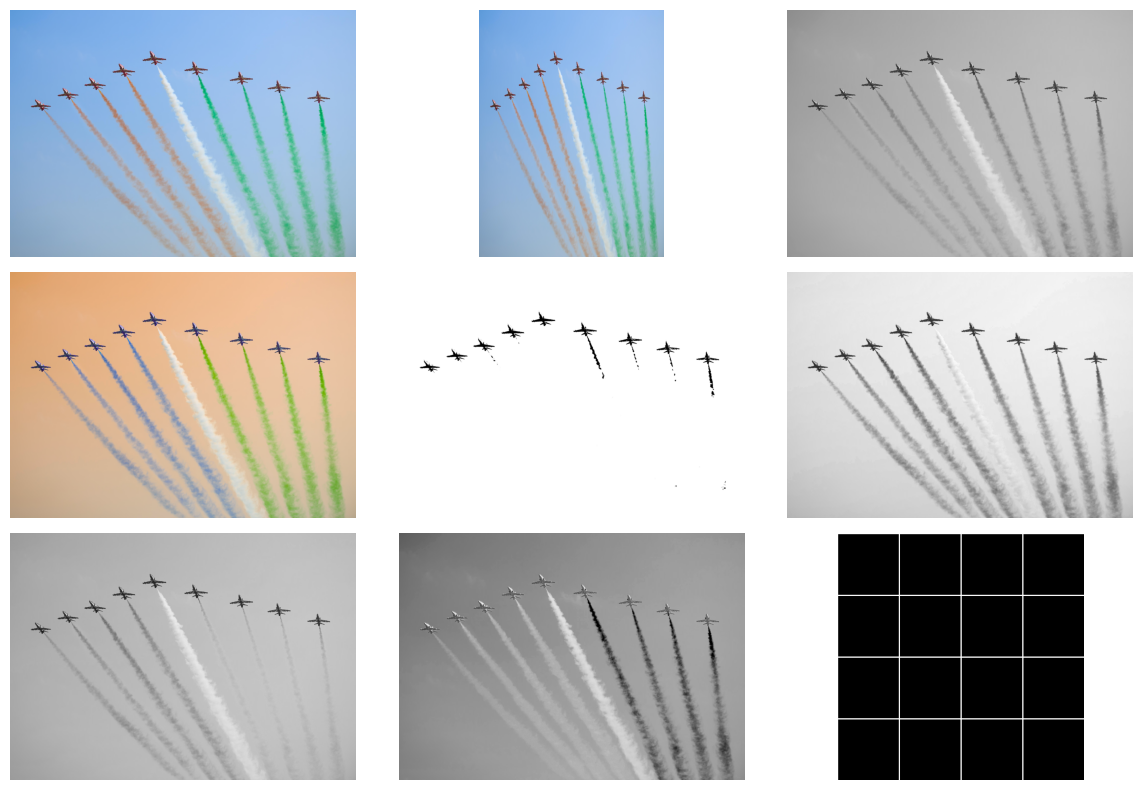

In [40]:
#1
import cv2
import matplotlib.pyplot as plt
import numpy as np

img = cv2.imread(r"C:\Users\Devesh Tripathi\OneDrive\Desktop\suryakiran.jpeg")
rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
resized = cv2.resize(img, (900, 1200))
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
_, bw = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY)
b, g, r = cv2.split(img)
reconstructed = cv2.merge((b,g,r))

data = np.zeros((200,200), dtype = np.uint8)
data[::50,:] = 255
data[:,::50] = 255
cv2.imwrite("image_2_D.png", data)

fig, ax = plt.subplots(3,3, figsize = (12, 8))
items = [ rgb, cv2.cvtColor(resized, cv2.COLOR_BGR2RGB), gray, reconstructed, bw, b,g,r, data]

for a, im in zip(ax.flat, items):
    a.imshow(im, cmap= "gray" if im.ndim==2 else None)
    a.axis("off")
plt.tight_layout()
plt.show()

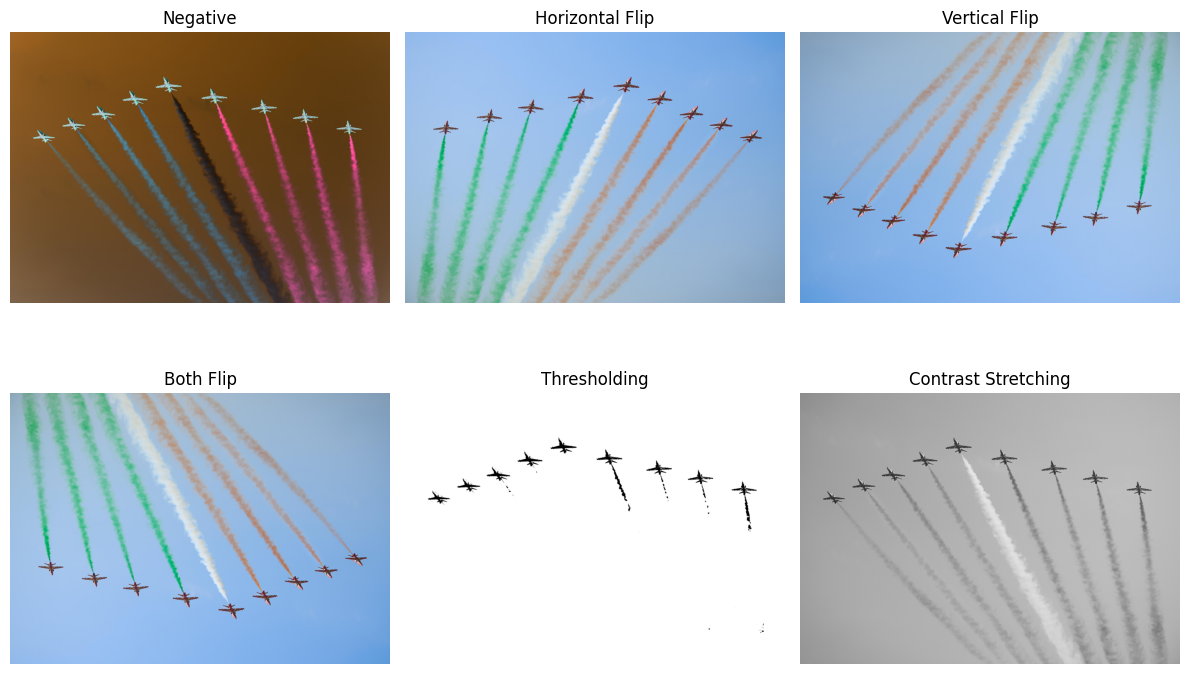

In [42]:
#2
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread(r"C:\Users\Devesh Tripathi\OneDrive\Desktop\suryakiran.jpeg")

rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

negative = 255 - rgb

horizontal = cv2.flip(rgb, 1)
vertical = cv2.flip(rgb, 0)
both = cv2.flip(rgb, -1)

_, threshold = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY)

low, high = gray.min(), gray.max()

contrast = ((gray - low) / (high - low) * 255).astype(np.uint8)

fig, ax = plt.subplots(2, 3, figsize=(12, 8))

for a, im, title in zip(
    ax.flat,
    [negative, horizontal, vertical, both, threshold, contrast],
    ["Negative", "Horizontal Flip", "Vertical Flip", "Both Flip",
     "Thresholding", "Contrast Stretching"]
):
    a.imshow(im, cmap="gray" if im.ndim == 2 else None)
    a.set_title(title)
    a.axis("off")

plt.tight_layout()
plt.show()

Mean value of image: 15.63


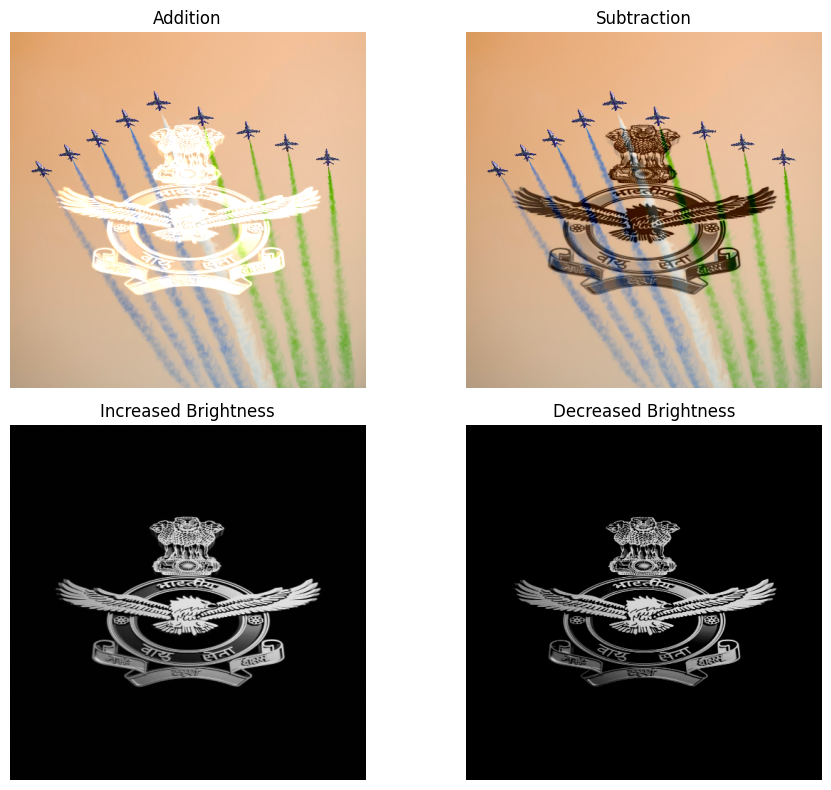

In [46]:
#3
import cv2
import numpy as np
import matplotlib.pyplot as plt

img1 = cv2.resize(cv2.imread(r"C:\Users\Devesh Tripathi\OneDrive\Desktop\suryakiran.jpeg"), (500, 500))
img2 = cv2.resize(cv2.imread(r"C:\Users\Devesh Tripathi\OneDrive\Desktop\iaf.jpg"), (500, 500))

added = cv2.add(img1, img2)
subtracted = cv2.subtract(img1, img2)

gray = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)
mean_value = np.mean(gray)

bright = cv2.add(gray, 50)
dark = cv2.subtract(gray, 50)

print(f"Mean value of image: {mean_value:.2f}")

fig, ax = plt.subplots(2, 2, figsize=(10, 8))

for a, im, title in zip(
    ax.flat,
    [added, subtracted, bright, dark],
    ["Addition", "Subtraction", "Increased Brightness", "Decreased Brightness"]
):
    a.imshow(im, cmap="gray" if im.ndim == 2 else None)
    a.set_title(title)
    a.axis("off")

plt.tight_layout()
plt.show()

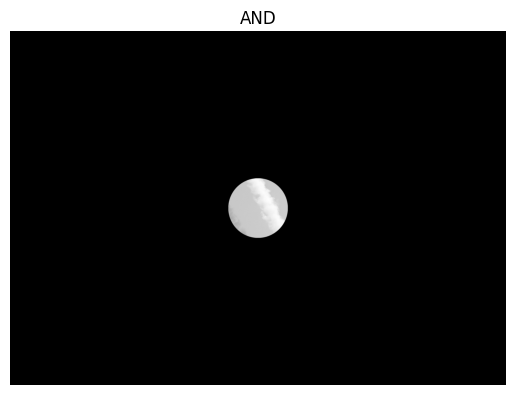

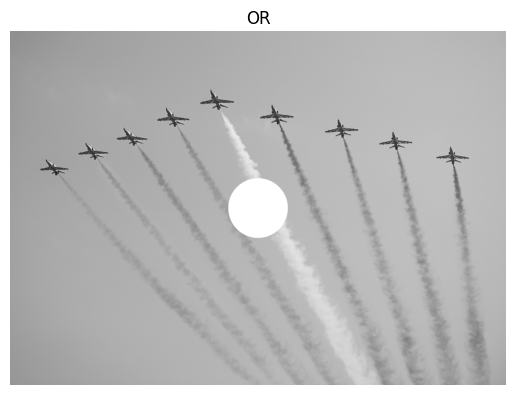

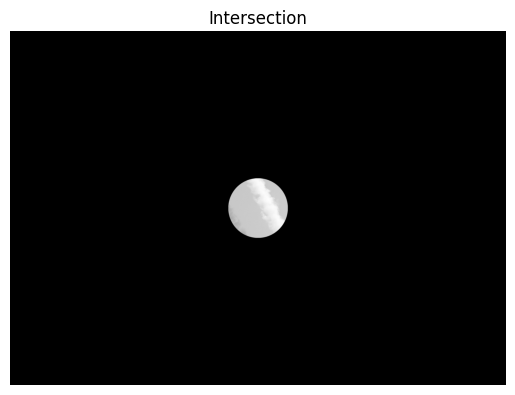

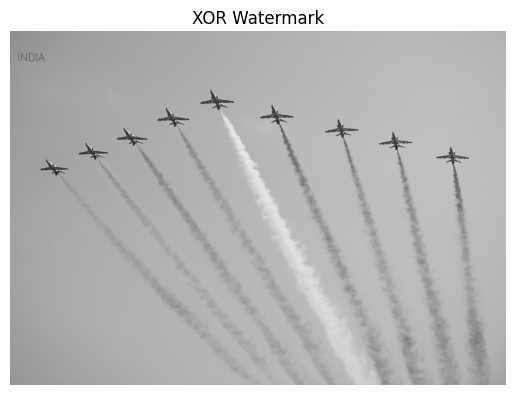

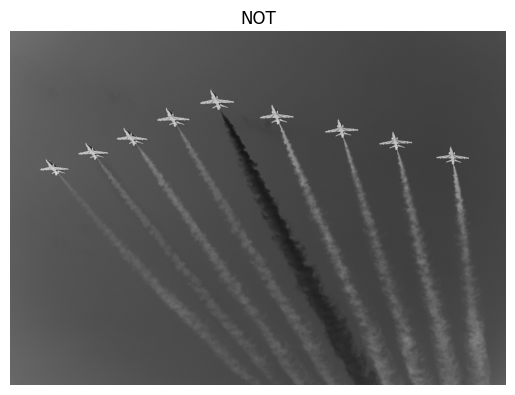

In [49]:
#4
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread(r"C:\Users\Devesh Tripathi\OneDrive\Desktop\suryakiran.jpeg", cv2.IMREAD_GRAYSCALE)

mask = np.zeros(img.shape, dtype=np.uint8)

cv2.circle(mask, (img.shape[1]//2, img.shape[0]//2), 250, 255, -1)

and_img = cv2.bitwise_and(img, mask)
or_img = cv2.bitwise_or(img, mask)
intersection = cv2.bitwise_and(img, mask)

watermark = np.zeros(img.shape, dtype=np.uint8)

cv2.putText(watermark, "INDIA", (60, 250),
            cv2.FONT_HERSHEY_SIMPLEX, 3, 255, 6)

xor_img = cv2.bitwise_xor(img, watermark)
not_img = cv2.bitwise_not(img)

for title, result in [
    ("AND", and_img),
    ("OR", or_img),
    ("Intersection", intersection),
    ("XOR Watermark", xor_img),
    ("NOT", not_img)
]:
    plt.figure()
    plt.imshow(result, cmap="gray")
    plt.title(title)
    plt.axis("off")

plt.show()

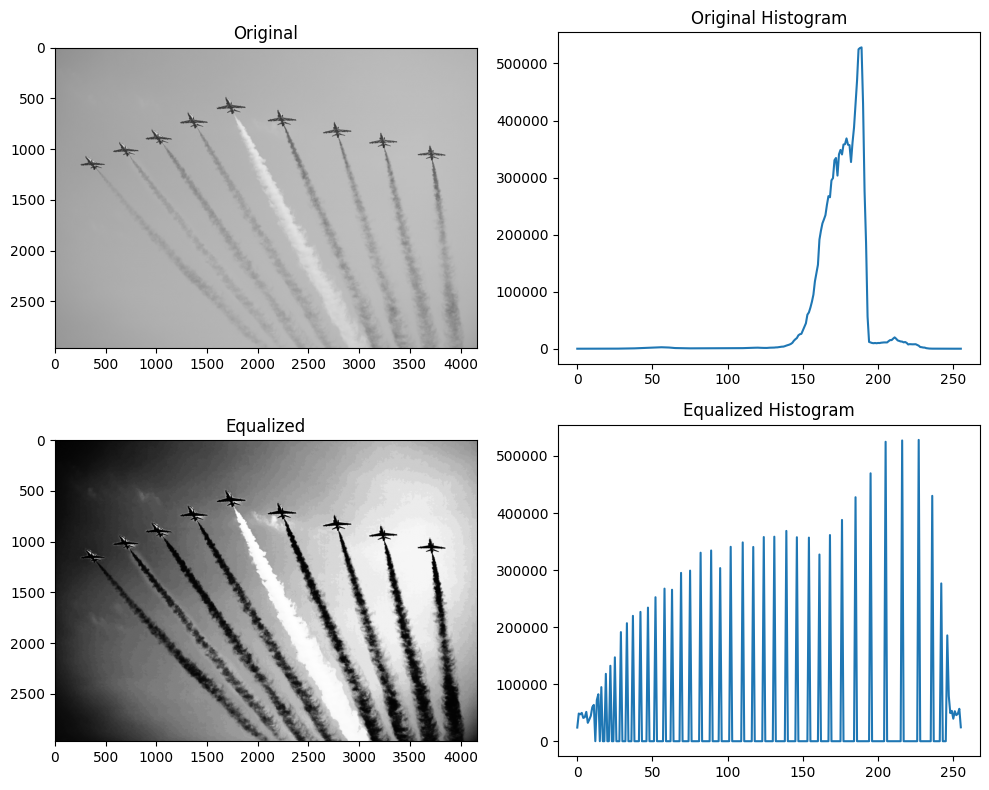

In [51]:
#5
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread(r"C:\Users\Devesh Tripathi\OneDrive\Desktop\suryakiran.jpeg", cv2.IMREAD_GRAYSCALE)

hist = cv2.calcHist([img], [0], None, [256], [0, 256])

equalized = cv2.equalizeHist(img)

hist_eq = cv2.calcHist([equalized], [0], None, [256], [0, 256])

# Manual histogram equalization
counts = np.bincount(img.ravel(), minlength=256)

cdf = counts.cumsum()

cdf_min = cdf[cdf > 0].min()

lookup = np.round((cdf - cdf_min) / (img.size - cdf_min) * 255)

manual = lookup[img].astype(np.uint8)

fig, ax = plt.subplots(2, 2, figsize=(10, 8))

ax[0, 0].imshow(img, cmap="gray")
ax[0, 0].set_title("Original")

ax[0, 1].plot(hist)
ax[0, 1].set_title("Original Histogram")

ax[1, 0].imshow(equalized, cmap="gray")
ax[1, 0].set_title("Equalized")

ax[1, 1].plot(hist_eq)
ax[1, 1].set_title("Equalized Histogram")

plt.tight_layout()
plt.show()

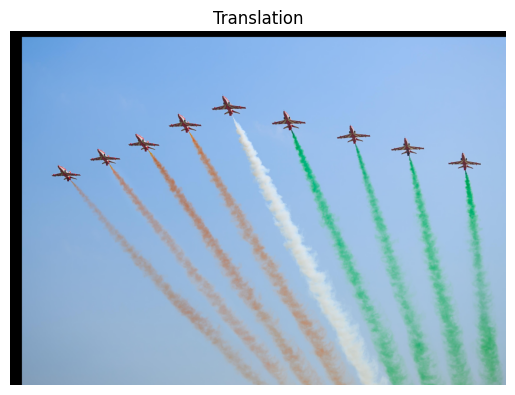

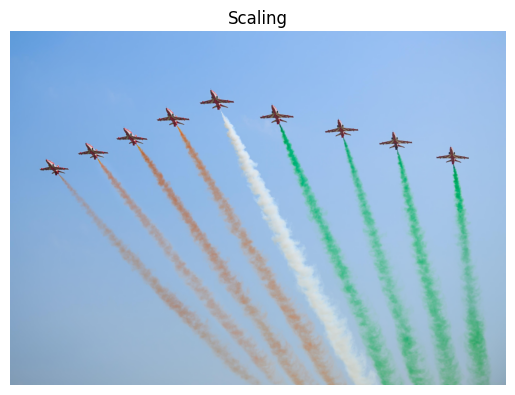

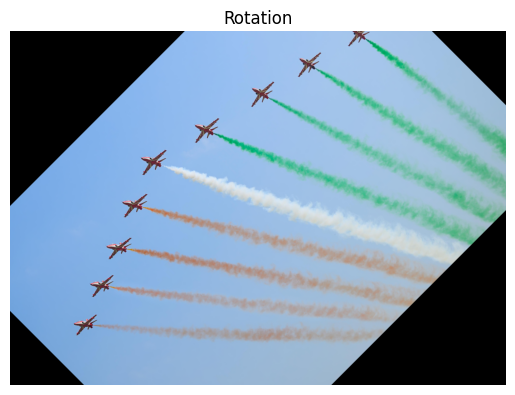

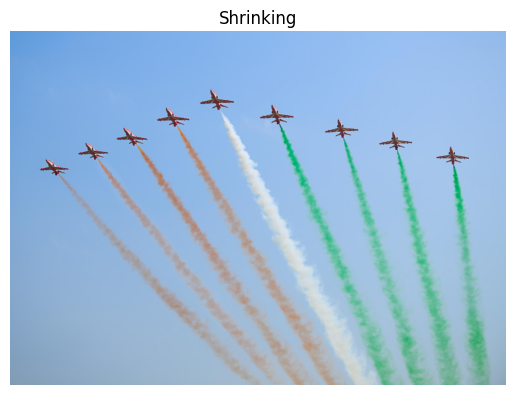

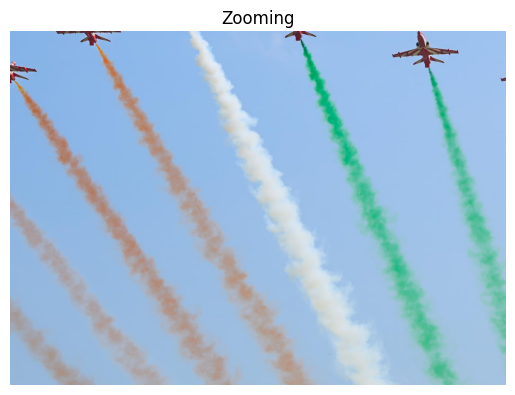

In [53]:
#6
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread(r"C:\Users\Devesh Tripathi\OneDrive\Desktop\suryakiran.jpeg")

rows, cols = img.shape[:2]

M = np.float32([[1, 0, 100], [0, 1, 50]])

translated = cv2.warpAffine(img, M, (cols, rows))

scaled = cv2.resize(img, None, fx=1.5, fy=1.5)

center = (cols//2, rows//2)

R = cv2.getRotationMatrix2D(center, 45, 1.0)

rotated = cv2.warpAffine(img, R, (cols, rows))

shrunk = cv2.resize(img, None, fx=0.5, fy=0.5)

crop = img[rows//4:3*rows//4, cols//4:3*cols//4]

zoomed = cv2.resize(crop, (cols, rows), interpolation=cv2.INTER_CUBIC)

for title, result in [
    ("Translation", translated),
    ("Scaling", scaled),
    ("Rotation", rotated),
    ("Shrinking", shrunk),
    ("Zooming", zoomed)
]:
    plt.figure()
    plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")

plt.show()

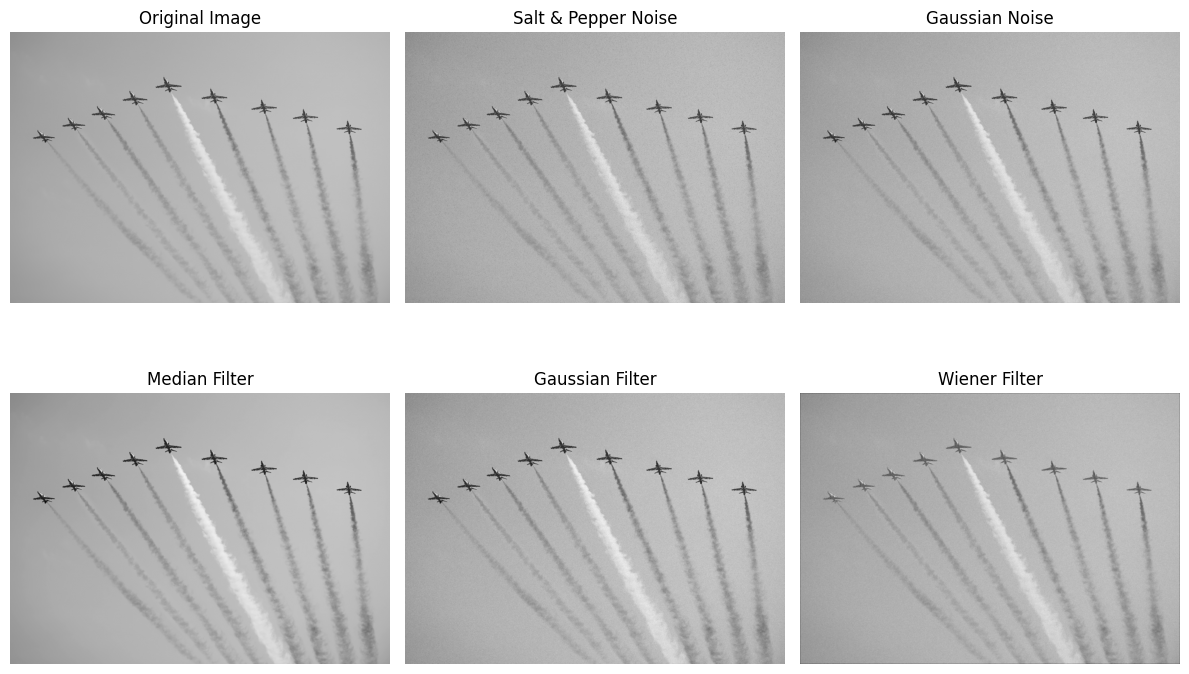

In [3]:
#7
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import wiener

gray = cv2.imread(
    r"C:\Users\Devesh Tripathi\OneDrive\Desktop\suryakiran.jpeg",
    cv2.IMREAD_GRAYSCALE
)

rng = np.random.default_rng(7)

sp = gray.copy()

n = int(0.02 * gray.size)

ys = rng.integers(0, gray.shape[0], n)
xs = rng.integers(0, gray.shape[1], n)

sp[ys, xs] = 255

ys = rng.integers(0, gray.shape[0], n)
xs = rng.integers(0, gray.shape[1], n)

sp[ys, xs] = 0

gaussian = np.clip(
    gray + rng.normal(0, 22, gray.shape),
    0, 255
).astype(np.uint8)

restored = cv2.blur(gaussian, (5, 5))

sp_removed = cv2.medianBlur(sp, 5)

gaussian_removed = cv2.GaussianBlur(gaussian, (5, 5), 0)

median = cv2.medianBlur(sp, 5)

wiener_img = np.clip(
    wiener(gaussian, (5, 5)),
    0, 255
).astype(np.uint8)

# Display output
fig, ax = plt.subplots(2, 3, figsize=(12, 8))

images = [
    gray,
    sp,
    gaussian,
    sp_removed,
    gaussian_removed,
    wiener_img
]

titles = [
    "Original Image",
    "Salt & Pepper Noise",
    "Gaussian Noise",
    "Median Filter",
    "Gaussian Filter",
    "Wiener Filter"
]

for a, im, title in zip(ax.flat, images, titles):
    a.imshow(im, cmap="gray")
    a.set_title(title)
    a.axis("off")

plt.tight_layout()
plt.show()

1-D convolution: [ 2  2  2  2  0 -2 -2 -2 -2]


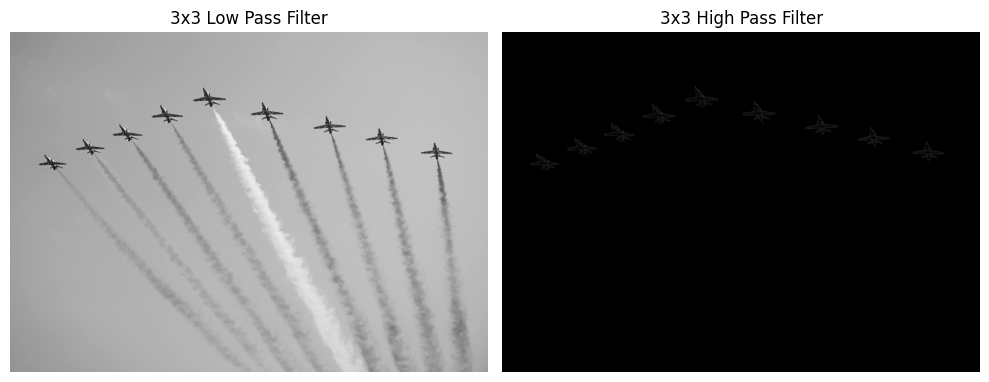

In [57]:
#8
import cv2
import numpy as np
import matplotlib.pyplot as plt

gray = cv2.imread(r"C:\Users\Devesh Tripathi\OneDrive\Desktop\suryakiran.jpeg", cv2.IMREAD_GRAYSCALE)

signal_1d = np.array([1, 2, 3, 4, 5, 4, 3, 2, 1])

kernel_1d = np.array([1, 0, -1])

conv_1d = np.convolve(signal_1d, kernel_1d, mode="same")

print("1-D convolution:", conv_1d)

low_pass_mask = np.ones((3, 3), np.float32) / 9

high_pass_mask = np.array(
    [[0, -1, 0],
     [-1, 4, -1],
     [0, -1, 0]],
    dtype=np.float32
)

low_pass = cv2.filter2D(gray, -1, low_pass_mask)

high_pass = cv2.filter2D(gray, -1, high_pass_mask)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].imshow(low_pass, cmap="gray")
ax[0].set_title("3x3 Low Pass Filter")

ax[1].imshow(high_pass, cmap="gray")
ax[1].set_title("3x3 High Pass Filter")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

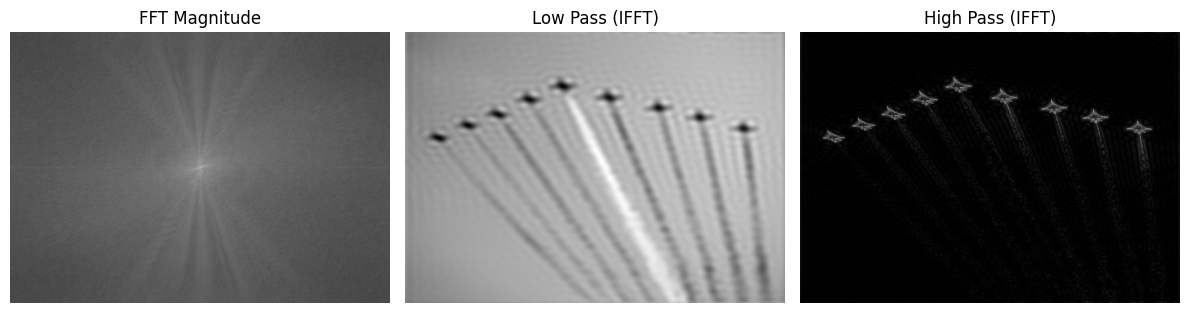

In [5]:
#9
import cv2
import numpy as np
import matplotlib.pyplot as plt

gray = cv2.imread(r"C:\Users\Devesh Tripathi\OneDrive\Desktop\suryakiran.jpeg", cv2.IMREAD_GRAYSCALE)

rows, cols = gray.shape

dft = np.fft.fftshift(np.fft.fft2(gray))

magnitude = np.log(np.abs(dft) + 1)

y, x = np.ogrid[:rows, :cols]

distance = np.sqrt((y - rows//2)**2 + (x - cols//2)**2)

radius = 35

low_mask = distance <= radius
high_mask = distance > radius

low_dft = dft * low_mask
high_dft = dft * high_mask

low_image = np.abs(np.fft.ifft2(np.fft.ifftshift(low_dft)))
high_image = np.abs(np.fft.ifft2(np.fft.ifftshift(high_dft)))

fig, ax = plt.subplots(1, 3, figsize=(12, 4))

for a, im, title in zip(
    ax,
    [magnitude, low_image, high_image],
    ["FFT Magnitude", "Low Pass (IFFT)", "High Pass (IFFT)"]
):
    a.imshow(im, cmap="gray")
    a.set_title(title)
    a.axis("off")

plt.tight_layout()
plt.show()

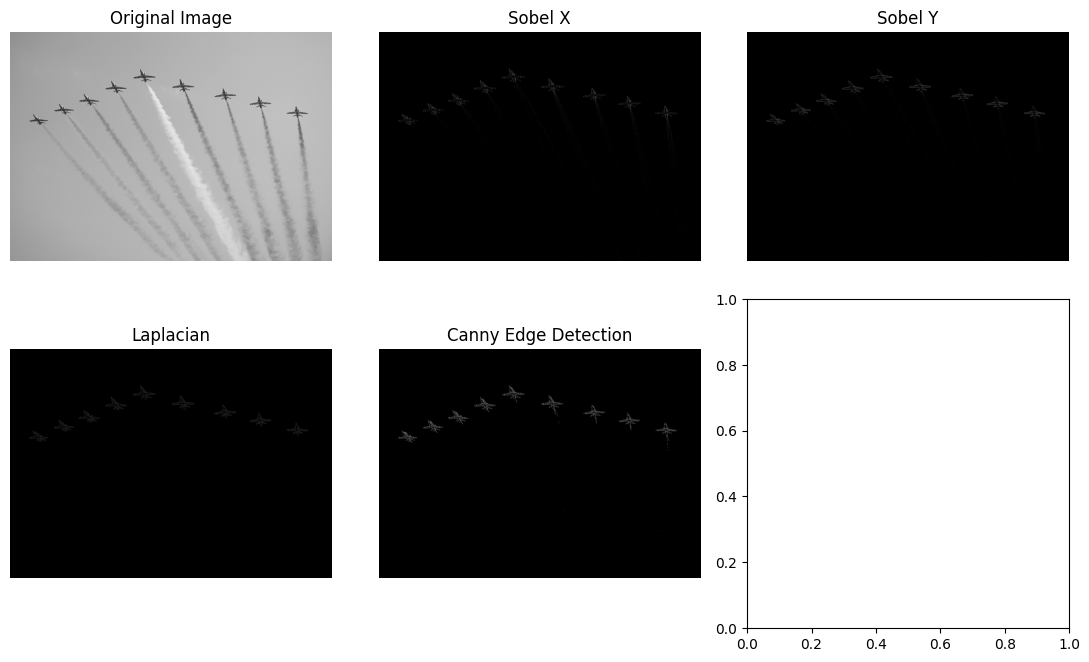

In [6]:
#10
import cv2
import numpy as np
import matplotlib.pyplot as plt

gray = cv2.imread(r"C:\Users\Devesh Tripathi\OneDrive\Desktop\suryakiran.jpeg", cv2.IMREAD_GRAYSCALE)
sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
laplacian = cv2.Laplacian(gray, cv2.CV_64F)
canny = cv2.Canny(gray, 80, 160)

results = [gray, np.abs(sobel_x), np.abs(sobel_y),
           np.abs(laplacian), canny]
titles = ["Original Image", "Sobel X", "Sobel Y",
          "Laplacian", "Canny Edge Detection"]
fig, ax = plt.subplots(2, 3, figsize=(11, 7))
for a, im, title in zip(ax.flat, results, titles):
    a.imshow(im, cmap="gray"); a.set_title(title); a.axis("off")
plt.tight_layout(); plt.show()

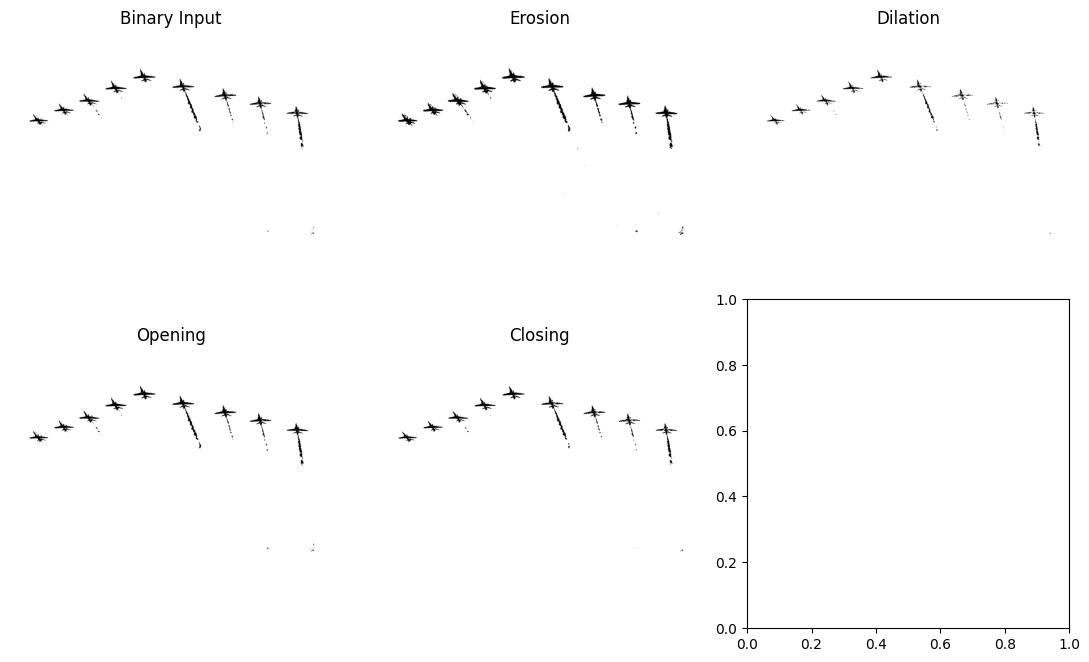

In [8]:
#11
import cv2
import numpy as np
import matplotlib.pyplot as plt

gray = cv2.imread(r"C:\Users\Devesh Tripathi\OneDrive\Desktop\suryakiran.jpeg", cv2.IMREAD_GRAYSCALE)
_, binary = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY)
kernel = np.ones((5, 5), dtype=np.uint8)
erosion = cv2.erode(binary, kernel, iterations=1)
dilation = cv2.dilate(binary, kernel, iterations=1)
opening = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)
closing = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)

fig, ax = plt.subplots(2, 3, figsize=(11, 7))
for a, im, title in zip(ax.flat,
    [binary, erosion, dilation, opening, closing],
    ["Binary Input", "Erosion", "Dilation", "Opening", "Closing"]):
    a.imshow(im, cmap="gray"); a.set_title(title); a.axis("off")
plt.tight_layout(); plt.show()